Cell 1: Setup

In [1]:
!pip install -q torch_geometric xgboost

import copy, json, os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, SAGEConv
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cuda


Cell 2: Drive aur paths

In [2]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/AtmoGraph'
DATA_PATH = f'{BASE}/gnn_dataset.npz'
RESULTS = f'{BASE}/results'
os.makedirs(RESULTS, exist_ok=True)

assert os.path.exists(DATA_PATH), "gnn_dataset.npz ko Drive ke AtmoGraph folder mein upload karo"
print("Dataset mil gaya")

Mounted at /content/drive
Dataset mil gaya


Cell 3: Data load karo


In [3]:
d = np.load(DATA_PATH)
x, y = d["x"], d["y"]                                   # x: (S, N, F), y: (S, N, 3)
edge_index = torch.tensor(d["edge_index"], dtype=torch.long)
split = d["split"]                                      # 0=train 1=val 2=test
feature_names = [str(f) for f in d["feature_names"]]
target_names = [str(t) for t in d["target_names"]]
meta = json.loads(str(d["meta"]))

S, N, Fdim = x.shape
H = y.shape[2]
Y_SCALE = float(meta["ripple_params"]["max_origin_delay_days"])   # delay ko 0-1 ke paas laane ke liye

print("⚠️ DATA LABEL:", meta["data_label"])
print(f"Scenarios={S}, Nodes={N}, Features={Fdim}, Targets={H}, Edges={edge_index.shape[1]}")

train_idx, val_idx, test_idx = [np.where(split == k)[0] for k in (0, 1, 2)]
print("Train/Val/Test scenarios:", len(train_idx), len(val_idx), len(test_idx))

def make_ds(idx):
    # Har scenario = ek chhota graph (same edges, alag x aur y)
    return [Data(x=torch.tensor(x[i]), edge_index=edge_index, y=torch.tensor(y[i])) for i in idx]

train_loader = DataLoader(make_ds(train_idx), batch_size=32, shuffle=True)
val_loader = DataLoader(make_ds(val_idx), batch_size=64)
test_loader = DataLoader(make_ds(test_idx), batch_size=64)

⚠️ DATA LABEL: SYNTHETIC / SIMULATED (delay labels ripple rule se bane hain)
Scenarios=500, Nodes=300, Features=11, Targets=3, Edges=528
Train/Val/Test scenarios: 350 75 75


Cell 4: Models aur training ke functions

In [4]:
HIDDEN = 64

class GNN(nn.Module):
    """GCN ya GraphSAGE: har layer node ko upstream neighbors se mila deti hai."""
    def __init__(self, kind, in_dim, hidden, out_dim, num_layers, dropout=0.1):
        super().__init__()
        Conv = GCNConv if kind == "gcn" else SAGEConv
        dims = [in_dim] + [hidden] * num_layers
        self.convs = nn.ModuleList([Conv(dims[i], dims[i + 1]) for i in range(num_layers)])
        self.head = nn.Linear(hidden, out_dim)          # 30/60/90 din ke 3 numbers
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.head(x)


class MLP(nn.Module):
    """BASELINE: graph ignore karta hai, sirf node ki apni features dekhta hai."""
    def __init__(self, in_dim, hidden, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, out_dim))

    def forward(self, x, edge_index=None):
        return self.net(x)


@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for b in loader:
        b = b.to(device)
        tot += F.mse_loss(model(b.x, b.edge_index), b.y / Y_SCALE, reduction="sum").item()
        n += b.y.numel()
    return tot / n


def train_model(model, name, epochs=150, lr=1e-3, patience=20):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    best_val, best_state, bad = float("inf"), None, 0
    hist = {"train": [], "val": []}
    for ep in range(1, epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for b in train_loader:
            b = b.to(device)
            opt.zero_grad()
            loss = F.mse_loss(model(b.x, b.edge_index), b.y / Y_SCALE)
            loss.backward()
            opt.step()
            tot += loss.item() * b.y.numel()
            n += b.y.numel()
        tr, va = tot / n, eval_loss(model, val_loader)
        hist["train"].append(tr)
        hist["val"].append(va)
        if va < best_val - 1e-6:                        # validation loss behtar hua
            best_val, best_state, bad = va, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:                         # early stopping
                break
        if ep % 20 == 0:
            print(f"  [{name}] epoch {ep}: train {tr:.5f} | val {va:.5f}")
    model.load_state_dict(best_state)                   # best wale weights wapas
    print(f"{name}: best val loss {best_val:.5f}")
    return hist, best_val


@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    for b in loader:
        b = b.to(device)
        ps.append((model(b.x, b.edge_index) * Y_SCALE).cpu())
        ys.append(b.y.cpu())
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

Cell 5: GNN aur MLP train karo


In [5]:
configs = {
    "GCN-4L":  dict(kind="gcn",  num_layers=4),
    "SAGE-4L": dict(kind="sage", num_layers=4),
    "SAGE-2L": dict(kind="sage", num_layers=2),   # kam layers = kam hops, comparison ke liye
}
models, histories, best_val = {}, {}, {}

for name, cfg in configs.items():
    m = GNN(cfg["kind"], Fdim, HIDDEN, H, cfg["num_layers"]).to(device)
    histories[name], best_val[name] = train_model(m, name)
    models[name] = m

mlp = MLP(Fdim, HIDDEN, H).to(device)
histories["MLP (no graph)"], _ = train_model(mlp, "MLP (no graph)")
models["MLP (no graph)"] = mlp

  [GCN-4L] epoch 20: train 0.00463 | val 0.00439
  [GCN-4L] epoch 40: train 0.00363 | val 0.00365
  [GCN-4L] epoch 60: train 0.00322 | val 0.00334
  [GCN-4L] epoch 80: train 0.00300 | val 0.00314
  [GCN-4L] epoch 100: train 0.00285 | val 0.00302
  [GCN-4L] epoch 120: train 0.00273 | val 0.00298
  [GCN-4L] epoch 140: train 0.00266 | val 0.00272
GCN-4L: best val loss 0.00267
  [SAGE-4L] epoch 20: train 0.00247 | val 0.00237
  [SAGE-4L] epoch 40: train 0.00153 | val 0.00137
  [SAGE-4L] epoch 60: train 0.00133 | val 0.00119
  [SAGE-4L] epoch 80: train 0.00117 | val 0.00104
  [SAGE-4L] epoch 100: train 0.00111 | val 0.00104
  [SAGE-4L] epoch 120: train 0.00105 | val 0.00094
  [SAGE-4L] epoch 140: train 0.00100 | val 0.00096
SAGE-4L: best val loss 0.00092
  [SAGE-2L] epoch 20: train 0.00436 | val 0.00445
  [SAGE-2L] epoch 40: train 0.00350 | val 0.00325
  [SAGE-2L] epoch 60: train 0.00300 | val 0.00286
  [SAGE-2L] epoch 80: train 0.00284 | val 0.00272
  [SAGE-2L] epoch 100: train 0.00276 | v

Cell 6: XGBoost aur mean baseline (dono graph ignore karte hain)

In [6]:
from xgboost import XGBRegressor

Xtr, Ytr = x[train_idx].reshape(-1, Fdim), y[train_idx].reshape(-1, H)
Xte = x[test_idx].reshape(-1, Fdim)
y_test = y[test_idx].reshape(-1, H)

xgb_pred = np.zeros((Xte.shape[0], H))
for h in range(H):                                       # har horizon ka alag model
    reg = XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                       subsample=0.8, random_state=SEED, n_jobs=-1)
    reg.fit(Xtr, Ytr[:, h])
    xgb_pred[:, h] = reg.predict(Xte)

mean_pred = np.tile(Ytr.mean(axis=0), (Xte.shape[0], 1))  # sabse simple baseline

Cell 7: Test metrics (sab models)

In [7]:
def compute_metrics(model_name, y_true, y_pred):
    y_pred = np.clip(y_pred, 0, None)                    # delay negative nahi ho sakti
    rows = []
    for h in range(H):
        for subset in ["all", "affected"]:
            yt, yp = y_true[:, h], y_pred[:, h]
            if subset == "affected":                     # sirf jahan asli delay > 0 thi
                mask = yt > 0
                yt, yp = yt[mask], yp[mask]
            rows.append(dict(model=model_name, subset=subset, horizon=target_names[h],
                             MAE=mean_absolute_error(yt, yp),
                             RMSE=float(np.sqrt(mean_squared_error(yt, yp))),
                             R2=r2_score(yt, yp)))
    return rows

preds = {"Mean baseline": mean_pred, "XGBoost (no graph)": xgb_pred}
for name, m in models.items():
    yt, yp = predict(m, test_loader)
    assert np.allclose(yt, y_test), "test order mismatch"
    preds[name] = yp

results = pd.DataFrame([r for n, p in preds.items() for r in compute_metrics(n, y_test, p)])

for subset in ["all", "affected"]:
    print(f"\n=== Test metrics, subset = {subset} (SYNTHETIC / SIMULATED labels) ===")
    t = results[results.subset == subset].pivot_table(index="model", columns="horizon",
                                                      values=["MAE", "RMSE", "R2"])
    print(t.reindex(list(preds)).round(3).to_string())


=== Test metrics, subset = all (SYNTHETIC / SIMULATED labels) ===
                         MAE                            R2                          RMSE                    
horizon            delay_30d delay_60d delay_90d delay_30d delay_60d delay_90d delay_30d delay_60d delay_90d
model                                                                                                       
Mean baseline          1.917     3.151     3.513    -0.000    -0.000    -0.000     5.238     6.143     6.314
XGBoost (no graph)     1.458     2.431     2.643     0.338     0.294     0.298     4.260     5.162     5.291
GCN-4L                 0.965     0.725     0.615     0.573     0.786     0.843     3.423     2.841     2.501
SAGE-4L                0.531     0.469     0.490     0.828     0.931     0.958     2.169     1.615     1.297
SAGE-2L                0.730     1.403     1.669     0.766     0.734     0.714     2.533     3.169     3.377
MLP (no graph)         1.354     2.446     2.703     0.334   

Cell 8: Plots, model aur results save karo

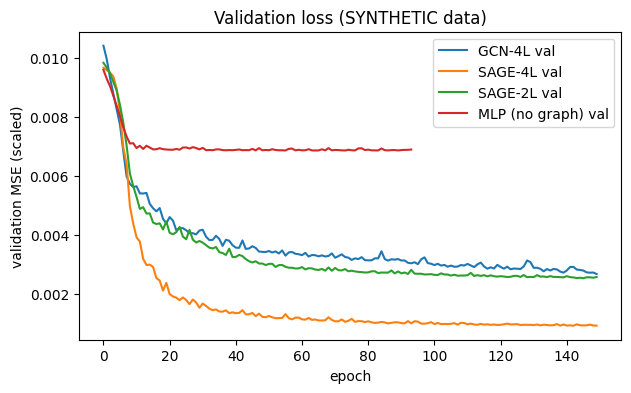

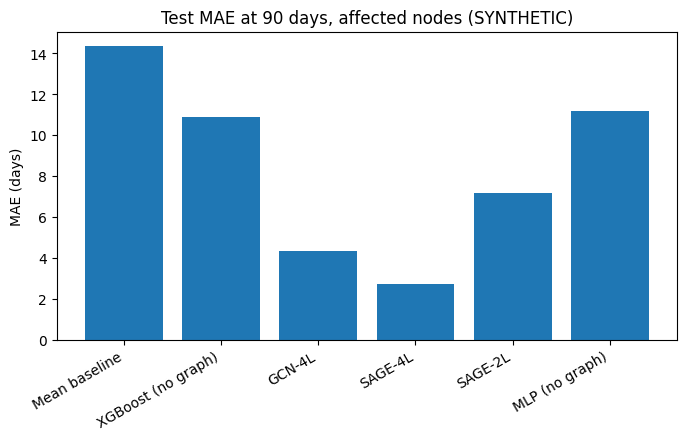

Best GNN (validation ke hisaab se): SAGE-4L


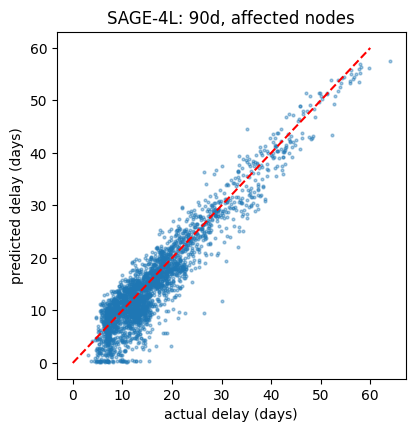

Saved in: /content/drive/MyDrive/AtmoGraph/results -> ['loss_curves.png', 'mae_comparison.png', 'pred_vs_actual.png', 'gnn.pt', 'metrics.csv', 'test_predictions.npz']


In [8]:
# --- Plot 1: training/validation loss ---
plt.figure(figsize=(7, 4))
for name, h in histories.items():
    plt.plot(h["val"], label=f"{name} val")
plt.xlabel("epoch"); plt.ylabel("validation MSE (scaled)")
plt.title("Validation loss (SYNTHETIC data)"); plt.legend()
plt.savefig(f"{RESULTS}/loss_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# --- Plot 2: 90 din ka MAE, affected nodes par ---
sub = results[(results.subset == "affected") & (results.horizon == "delay_90d")]
sub = sub.set_index("model").reindex(list(preds))
plt.figure(figsize=(8, 4))
plt.bar(sub.index, sub["MAE"])
plt.xticks(rotation=30, ha="right"); plt.ylabel("MAE (days)")
plt.title("Test MAE at 90 days, affected nodes (SYNTHETIC)")
plt.savefig(f"{RESULTS}/mae_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

# --- Best GNN: validation loss se chuna (test se nahi) ---
best_name = min(configs, key=lambda k: best_val[k])
print("Best GNN (validation ke hisaab se):", best_name)

yt, yp = y_test[:, 2], np.clip(preds[best_name][:, 2], 0, None)
idx = np.where(yt > 0)[0]
idx = np.random.default_rng(0).choice(idx, size=min(5000, len(idx)), replace=False)
plt.figure(figsize=(4.5, 4.5))
plt.scatter(yt[idx], yp[idx], s=4, alpha=0.4)
plt.plot([0, 60], [0, 60], "r--")
plt.xlabel("actual delay (days)"); plt.ylabel("predicted delay (days)")
plt.title(f"{best_name}: 90d, affected nodes")
plt.savefig(f"{RESULTS}/pred_vs_actual.png", dpi=150, bbox_inches="tight"); plt.show()

# --- Model, metrics, test predictions save ---
cfg = configs[best_name]
torch.save({
    "state_dict": {k: v.cpu() for k, v in models[best_name].state_dict().items()},
    "config": dict(kind=cfg["kind"], in_dim=Fdim, hidden=HIDDEN, out_dim=H, num_layers=cfg["num_layers"]),
    "y_scale": Y_SCALE, "horizons_days": meta["horizons_days"],
    "feature_names": feature_names, "name": best_name,
    "data_label": meta["data_label"],
}, f"{RESULTS}/gnn.pt")
results.to_csv(f"{RESULTS}/metrics.csv", index=False)
np.savez_compressed(f"{RESULTS}/test_predictions.npz",
                    y_true=y_test, y_pred=np.clip(preds[best_name], 0, None), test_idx=test_idx)
print("Saved in:", RESULTS, "->", os.listdir(RESULTS))